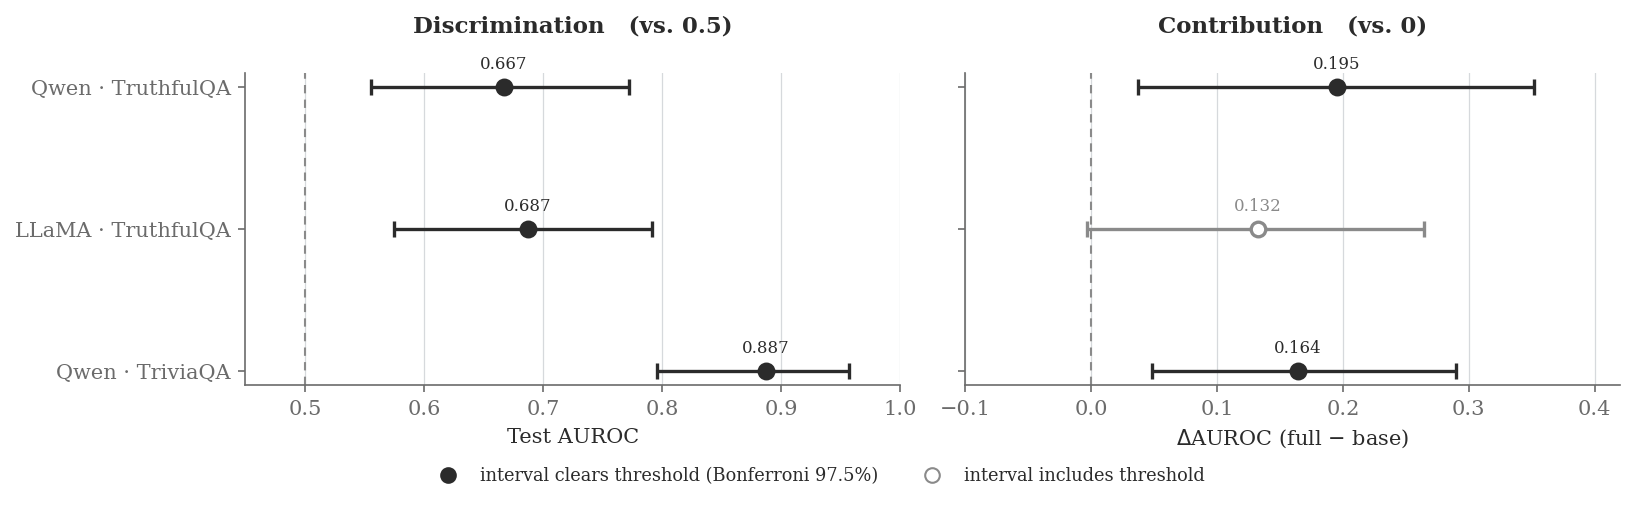

Saved /home/brandon/energy_llm/results/cross_experiment_forest.png


In [4]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- repo root (same detection as the experiment notebooks) ---
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "configs").exists():
    REPO_ROOT = REPO_ROOT.parent

EXPERIMENTS = ["e1", "e2", "e3"]
DISPLAY = {"e1": "Qwen · TruthfulQA",
           "e2": "LLaMA · TruthfulQA",
           "e3": "Qwen · TriviaQA"}

PALETTE = {"factual": "#3C6E8F", "halluc": "#B5544E", "ink": "#2B2B2B",
           "muted": "#6B6B6B", "grid": "#D6D9DC", "panel": "#F4F6F8"}
GRAY = "#8A8A8A"
plt.rcParams.update({
    "font.family": "serif", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": PALETTE["ink"], "axes.labelcolor": PALETTE["ink"],
    "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "figure.dpi": 150,
})

# --- read the three summaries ---
S = {exp: json.loads((REPO_ROOT / f"results/{exp}/analysis_summary.json").read_text())
     for exp in EXPERIMENTS}

ys = np.arange(len(EXPERIMENTS))[::-1]   # E1 on top

def draw_row(ax, x, lo, hi, y, passed):
    col = PALETTE["ink"] if passed else GRAY
    mfc = PALETTE["ink"] if passed else "white"
    ax.errorbar(x, y, xerr=[[x - lo], [hi - x]], fmt="o", ms=7, capsize=4,
                lw=1.6, color=col, markerfacecolor=mfc,
                markeredgecolor=col, markeredgewidth=1.6, zorder=3)
    ax.annotate(f"{x:.3f}", (x, y), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=8, color=col)

fig, (axd, axc) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)

# discrimination (vs 0.5)
for y, exp in zip(ys, EXPERIMENTS):
    s = S[exp]
    lo, hi = s["full"]["ci_97_5"]
    draw_row(axd, s["full"]["test_auroc"], lo, hi, y,
             s["confirmatory_bonferroni"]["discrimination"])
axd.axvline(0.5, color=GRAY, ls=(0, (4, 3)), lw=1.0, zorder=1)
axd.set_yticks(ys); axd.set_yticklabels([DISPLAY[e] for e in EXPERIMENTS])
axd.set_xlim(0.45, 1.0)
axd.set_xlabel("Test AUROC")
axd.set_title("Discrimination   (vs. 0.5)", pad=20)
axd.grid(axis="x", color=PALETTE["grid"], lw=0.6); axd.set_axisbelow(True)

# contribution (vs 0)
for y, exp in zip(ys, EXPERIMENTS):
    s = S[exp]
    lo, hi = s["delta_auroc"]["ci_97_5"]
    draw_row(axc, s["delta_auroc"]["point"], lo, hi, y,
             s["confirmatory_bonferroni"]["contribution"])
axc.axvline(0, color=GRAY, ls=(0, (4, 3)), lw=1.0, zorder=1)
axc.set_xlim(-0.10, 0.42)
axc.set_xlabel(r"$\Delta$AUROC (full $-$ base)")
axc.set_title("Contribution   (vs. 0)", pad=20)
axc.grid(axis="x", color=PALETTE["grid"], lw=0.6); axc.set_axisbelow(True)

# legend: filled = clears threshold, open = interval includes threshold
leg = [Line2D([0], [0], marker="o", ls="none", color=PALETTE["ink"], markersize=7,
              label="interval clears threshold (Bonferroni 97.5%)"),
       Line2D([0], [0], marker="o", ls="none", color=GRAY, markerfacecolor="white",
              markeredgecolor=GRAY, markersize=7,
              label="interval includes threshold")]
fig.legend(handles=leg, loc="lower center", bbox_to_anchor=(0.5, -0.06),
           ncol=2, frameon=False, fontsize=8.5)

fig.tight_layout()
out = REPO_ROOT / "results" / "cross_experiment_forest.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Saved", out)